# Library Used

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
import scipy.stats as stats
from scipy.stats import shapiro, jarque_bera

In [10]:
main = pd.read_csv('/content/drive/MyDrive/Prediksi Harga HP Multiple Linear Regression/Mobile-phone-price.csv')
df = main.copy()
df

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($)
0,Apple,iPhone 13 Pro,128 GB,6 GB,6.1,12 + 12 + 12,3095,999
1,Samsung,Galaxy S21 Ultra,256 GB,12 GB,6.8,108 + 10 + 10 + 12,5000,1199
2,OnePlus,9 Pro,128 GB,8 GB,6.7,48 + 50 + 8 + 2,4500,899
3,Xiaomi,Redmi Note 10 Pro,128 GB,6 GB,6.67,64 + 8 + 5 + 2,5020,279
4,Google,Pixel 6,128 GB,8 GB,6.4,50 + 12.2,4614,799
...,...,...,...,...,...,...,...,...
402,Samsung,Galaxy Note20 5G,128,8,6.7,12+64+12,4300,1049
403,Xiaomi,Mi 10 Lite 5G,128,6,6.57,48+8+2+2,4160,349
404,Apple,iPhone 12 Pro Max,128,6,6.7,12+12+12,3687,1099
405,Oppo,Reno3,128,8,6.4,48+13+8+2,4025,429


# Clean up Data

In [11]:
ada_duplikat = df.duplicated().any()
print("Apakah ada baris yang persis sama?", ada_duplikat)

# 2. Lihat berapa banyak baris duplikatnya
jumlah_duplikat = df.duplicated().sum()
print("Jumlah baris duplikat:", jumlah_duplikat)

# 3. Tampilkan baris-baris yang merupakan duplikat
baris_duplikat = df[df.duplicated(keep=False)] # keep=False agar semua kemunculannya tampil
print("\nDetail baris yang duplikat:")
print(baris_duplikat)

Apakah ada baris yang persis sama? True
Jumlah baris duplikat: 26

Detail baris yang duplikat:
        Brand                  Model Storage   RAM Screen Size (inches)  \
13      Apple         iPhone 12 Mini   64 GB  4 GB                  5.4   
38     Xiaomi         Poco M3 Pro 5G   64 GB  4 GB                  6.5   
45      Apple         iPhone 12 Mini   64 GB  4 GB                  5.4   
61     Xiaomi         Poco M3 Pro 5G   64 GB  4 GB                  6.5   
86      Nokia                   XR20   128GB   6GB                 6.67   
105      Oppo                    A16    32GB   3GB                 6.52   
107     Nokia               C20 Plus    32GB   3GB                  6.5   
130    Xiaomi  Redmi Note 10 Pro Max   128GB   8GB                 6.67   
132     Nokia                   XR20   128GB   6GB                 6.67   
136  Motorola       Moto G Stylus 5G   128GB   5GB                  6.8   
141      Vivo                   Y12s    32GB   3GB                 6.51   
165  

In [12]:
df[df['Model'] == 'Poco M3 Pro 5G']

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($)
38,Xiaomi,Poco M3 Pro 5G,64 GB,4 GB,6.5,48 + 2 + 2,5000,199
61,Xiaomi,Poco M3 Pro 5G,64 GB,4 GB,6.5,48 + 2 + 2,5000,199
110,Xiaomi,Poco M3 Pro 5G,128GB,6GB,6.5,48MP + 2MP + 2MP,5000,$199
137,Xiaomi,Poco M3 Pro 5G,64GB,4GB,6.5,48MP + 2MP + 2MP,5000,$179


In [13]:
#Storage
df['Storage'] = df['Storage'].str.replace(r'\D+','', regex=True)
# ubah jadi angka biar bisa di describe
df['Storage'] = pd.to_numeric(df['Storage'], errors='coerce')

#Ram
df['RAM'] = df['RAM'].str.replace(r'\D+','', regex=True)
df['RAM'] = pd.to_numeric(df['RAM'], errors='coerce')

#Screen Size
df["Screen Size (inches)"] = df["Screen Size (inches)"].str.replace(r"[^\d.]", "", regex=True)
df['Screen Size (inches)'] = pd.to_numeric(df['Screen Size (inches)'], errors='coerce')

#Camera
# 1. Hapus teks khusus seperti '3D' atau 'ToF' terlebih dahulu
df["Camera_Clean"] = (
    df["Camera (MP)"].astype(str).str.replace(r"\d*D|\d*ToF", "", regex=True)
)
# 2. Hapus semua huruf tersisa (a-z dan A-Z) serta spasi
df["Camera_Clean"] = (
    df["Camera_Clean"]
    .str.replace(r"[a-zA-Z]+", "", regex=True)  # Sudah diperbaiki dari a-zA-A
    .str.replace(" ", "")
)

#Price
## bersihkan data dari $
df["Price ($)"] = (
    df["Price ($)"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

In [14]:
#dealing with duplicate values

#keep first value
#keep only when brand and model same
df = df.drop_duplicates(
    subset=[
        "Brand",
        "Model",
    ],
    keep="first",
).reset_index(drop=True)

#Cek kembali apakah masih ada baris duplikat
print("Apakah masih ada baris duplikat?:", df.duplicated().any())
print("Jumlah baris setelah dibersihkan:", len(df))

Apakah masih ada baris duplikat?: False
Jumlah baris setelah dibersihkan: 239


In [15]:
df[df['Model'] == 'A54']

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Camera_Clean
53,Oppo,A54,128,4,6.51,13 + 2 + 2,5000,239,13+2+2


# Column Description

In [16]:
df.isnull().sum()

,0
Brand,0
Model,0
Storage,0
RAM,0
Screen Size (inches),1
Camera (MP),0
Battery Capacity (mAh),0
Price ($),0
Camera_Clean,0


## Brand

In [17]:
df['Brand'].unique()

array(['Apple', 'Samsung', 'OnePlus', 'Xiaomi', 'Google', 'Oppo', 'Vivo',
       'Realme', 'Motorola', 'Nokia', 'Sony', 'LG', 'Asus', 'Blackberry',
       'CAT', 'Huawei'], dtype=object)

In [18]:
df['Brand'].nunique()

16

In [19]:
pd.concat(
    [
        df["Brand"].value_counts(),
        df["Brand"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)

,Count,Percentage (%)
Brand,,
Samsung,42,17.57
Xiaomi,33,13.81
Oppo,33,13.81
Realme,24,10.04
Vivo,21,8.79
Motorola,19,7.95
Nokia,17,7.11
Apple,15,6.28
Huawei,10,4.18


## Model

In [20]:
df['Model'].unique()

array(['iPhone 13 Pro', 'Galaxy S21 Ultra', '9 Pro', 'Redmi Note 10 Pro',
       'Pixel 6', 'iPhone 13', 'Galaxy Z Flip3', 'Poco X3 Pro',
       'Reno6 Pro+ 5G', 'X70 Pro+', 'Nord CE 5G', 'Galaxy A52s 5G',
       'GT Neo2', 'iPhone 12 Mini', 'Find X3 Pro', 'Mi 11 Lite 5G NE',
       'Galaxy S21', 'Y20s (G)', '8s 5G', 'A94', 'Redmi 10 Prime',
       'Galaxy A22 5G', 'Narzo 50 Pro 5G', '9', 'Redmi Note 10 Pro Max',
       'iPhone 11', 'Galaxy A03s', 'A74 5G', 'Y12s (2021)', '9i',
       'Galaxy M52 5G', 'Redmi 10', 'iPhone SE (2nd Gen)', 'A53s', 'Y33s',
       'C25s', 'Galaxy A22 4G', 'Nord 2 5G', 'Poco M3 Pro 5G',
       'iPhone XR', 'A16', 'C21Y', 'Galaxy F22', 'F19 Pro+ 5G', 'Mi 11X',
       'V21e', '8 5G', 'Galaxy M12', 'A16s', 'Redmi 9 Power',
       'iPhone 11 Pro Max', 'Y20G', 'Narzo 50i', 'A54', 'Redmi 9T',
       'iPhone 13 Pro Max', 'Y33', 'Galaxy A72', 'Reno6 Pro 5G',
       'iPhone SE (2020)', 'Y53s', '7i', 'Galaxy A52 5G', 'F19 Pro',
       'Redmi Note 10S', 'Y21s', 'Mi 11 L

In [21]:
df["Model"].nunique()

239

In [22]:
pd.concat(
    [
        df["Model"].value_counts(),
        df["Model"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],).head(10)

,Count,Percentage (%)
Model,,
iPhone 13 Pro,1,0.42
Galaxy S21 Ultra,1,0.42
9 Pro,1,0.42
Redmi Note 10 Pro,1,0.42
Pixel 6,1,0.42
iPhone 13,1,0.42
Galaxy Z Flip3,1,0.42
Poco X3 Pro,1,0.42
Reno6 Pro+ 5G,1,0.42


## Storage

In [23]:
df['Storage'].unique()

array([128, 256,  64,  32, 512])

In [24]:
df['Storage'].nunique()

5

In [25]:
sorted(df['Storage'].unique())

[np.int64(32), np.int64(64), np.int64(128), np.int64(256), np.int64(512)]

In [26]:
dist_storage = pd.concat(
    [
        df["Storage"].value_counts(),
        df["Storage"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_storage

,Count,Percentage (%)
Storage,,
128,138,57.74
64,46,19.25
256,32,13.39
32,21,8.79
512,2,0.84


In [27]:
df['Storage'].describe()

,Storage
count,239.000000
mean,127.598326
std,71.040095
min,32.000000
25%,64.000000
50%,128.000000
75%,128.000000
max,512.000000


In [28]:
df['Storage'].median()

128.0

In [29]:
df['Storage'].mode()

,Storage
0,128


In [30]:
# Skewness
skew = df['Storage'].skew()

# Kurtosis
kurt = df['Storage'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Storage'].quantile(0.25)
q3 = df['Storage'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Storage'].mean()

# Std (Simpangan Baku)
std = df['Storage'].std()

# Median (Nilai Tengah)
median = df['Storage'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Storage'].mode()[0]

print(f"Mean   : {mean}")
print(f"Std    : {std}")
print(f"Median : {median}")
print(f"Mode   : {mode}")
print(f"Skewness : {skew}")
print(f"Kurtosis : {kurt}")
print(f"IQR      : {iqr}")

Mean   : 127.59832635983264
Std    : 71.04009518038094
Median : 128.0
Mode   : 128
Skewness : 1.786534653905859
Kurtosis : 6.2455069032039825
IQR      : 64.0


Text(0.5, 0, 'Storage')

<Figure size 2000x1200 with 0 Axes>

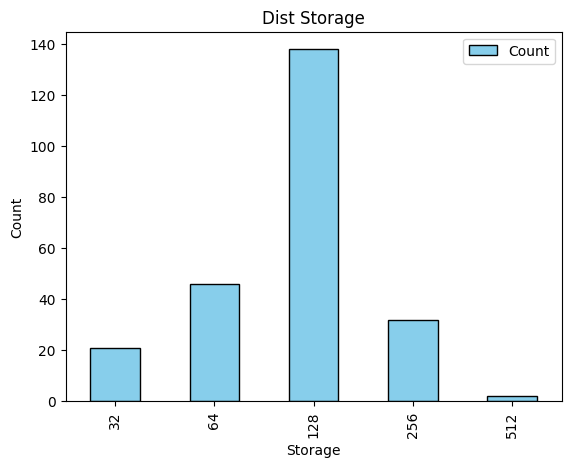

In [31]:
plt.figure(figsize=(20, 12))

dist_storage.sort_index().plot(
    kind="bar", y="Count", color="skyblue", edgecolor="black"
)
plt.title('Dist Storage')
plt.ylabel("Count")
plt.xlabel("Storage")

## RAM

In [32]:
df['RAM'].unique()

array([ 6, 12,  8,  4,  3,  2,  5, 16])

In [33]:
df['RAM'].unique()

array([ 6, 12,  8,  4,  3,  2,  5, 16])

In [34]:
df['RAM'].nunique()

8

In [35]:
dist_ram = pd.concat(
    [
        df["RAM"].value_counts(),
        df["RAM"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_ram

,Count,Percentage (%)
RAM,,
4,67,28.03
6,61,25.52
8,61,25.52
3,23,9.62
12,17,7.11
2,8,3.35
5,1,0.42
16,1,0.42


In [36]:
# Skewness
skew = df['RAM'].skew()

# Kurtosis
kurt = df['RAM'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['RAM'].quantile(0.25)
q3 = df['RAM'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['RAM'].mean()

# Std (Simpangan Baku)
std = df['RAM'].std()

# Median (Nilai Tengah)
median = df['RAM'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['RAM'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 5.99163179916318
Std = 2.5601858385133034
Median = 6.0
Mode = 4
Skewness = 0.8911069482471606
Kurtosis = 0.7840586170345563
IQR = 4.0


In [37]:
df['RAM'].describe()

,RAM
count,239.000000
mean,5.991632
std,2.560186
min,2.000000
25%,4.000000
50%,6.000000
75%,8.000000
max,16.000000


Text(0.5, 0, 'RAM')

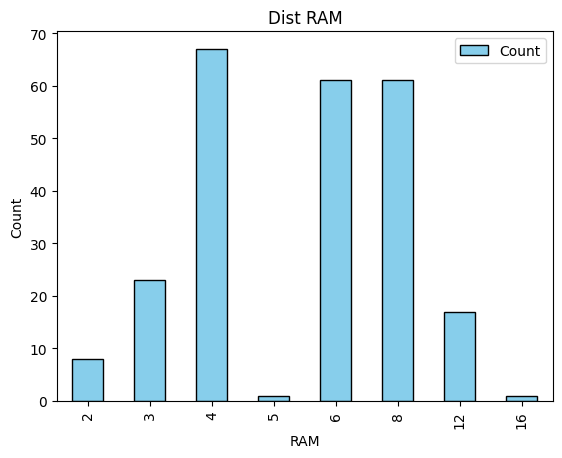

In [38]:
dist_ram.sort_index().plot(
    kind="bar", y="Count", color="skyblue", edgecolor="black"
)
plt.title('Dist RAM')
plt.ylabel("Count")
plt.xlabel("RAM")

## Screen Size (inches)

In [39]:
df['Screen Size (inches)'].unique()

array([6.1 , 6.8 , 6.7 , 6.67, 6.4 , 6.55, 6.78, 6.43, 6.5 , 6.62, 5.4 ,
       6.2 , 6.51, 6.6 , 4.7 , 6.58, 6.52, 6.44, 6.53, 6.56,  nan, 4.5 ,
       6.39, 5.9 , 5.5 , 6.81, 5.99, 6.82, 6.3 , 6.22, 6.  , 6.35, 6.9 ,
       6.76, 6.49, 6.72, 5.7 , 6.47, 7.6 , 6.15, 6.57])

In [40]:
df["Screen Size (inches)"].unique()

array([6.1 , 6.8 , 6.7 , 6.67, 6.4 , 6.55, 6.78, 6.43, 6.5 , 6.62, 5.4 ,
       6.2 , 6.51, 6.6 , 4.7 , 6.58, 6.52, 6.44, 6.53, 6.56,  nan, 4.5 ,
       6.39, 5.9 , 5.5 , 6.81, 5.99, 6.82, 6.3 , 6.22, 6.  , 6.35, 6.9 ,
       6.76, 6.49, 6.72, 5.7 , 6.47, 7.6 , 6.15, 6.57])

In [41]:
df["Screen Size (inches)"].nunique()

40

In [42]:
dist_screen = pd.concat(
    [
        df["Screen Size (inches)"].value_counts(),
        df["Screen Size (inches)"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_screen.head(10)

,Count,Percentage (%)
Screen Size (inches),,
6.50,53,22.27
6.70,18,7.56
6.40,18,7.56
6.55,15,6.30
6.67,15,6.30
6.43,14,5.88
6.51,10,4.20
6.60,8,3.36
6.53,8,3.36


In [43]:
df['Screen Size (inches)'].describe()

,Screen Size (inches)
count,238.000000
mean,6.472143
std,0.337401
min,4.500000
25%,6.430000
50%,6.500000
75%,6.600000
max,7.600000


In [44]:
# Skewness
skew = df['Screen Size (inches)'].skew()

# Kurtosis
kurt = df['Screen Size (inches)'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Screen Size (inches)'].quantile(0.25)
q3 = df['Screen Size (inches)'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Screen Size (inches)'].mean()

# Std (Simpangan Baku)
std = df['Screen Size (inches)'].std()

# Median (Nilai Tengah)
median = df['Screen Size (inches)'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Screen Size (inches)'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 6.472142857142857
Std = 0.33740138201538994
Median = 6.5
Mode = 6.5
Skewness = -3.2824583162373635
Kurtosis = 16.048189960579975
IQR = 0.16999999999999993


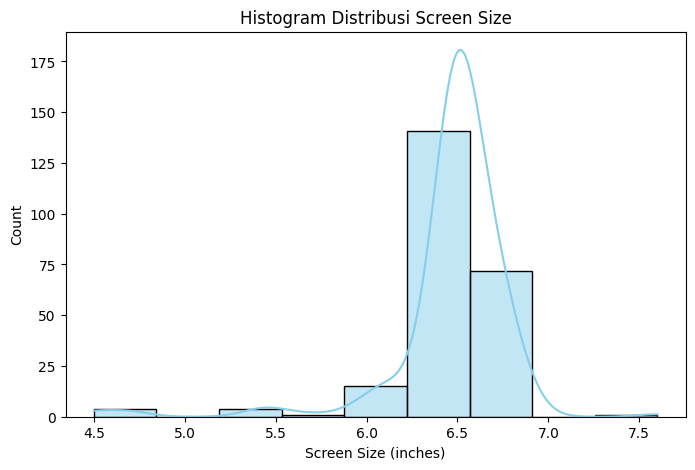

In [45]:
plt.figure(figsize=(8, 5))
# Membuat histogram dengan kurva tren (KDE)
sns.histplot(
    df["Screen Size (inches)"], bins='sturges', color="skyblue", kde=True
)

plt.title("Histogram Distribusi Screen Size")
plt.xlabel("Screen Size (inches)")
plt.ylabel("Count")
plt.show()

## Camera (MP)

In [46]:
df['Camera (MP)'].unique()

array(['12 + 12 + 12', '108 + 10 + 10 + 12', '48 + 50 + 8 + 2',
       '64 + 8 + 5 + 2', '50 + 12.2', '12 + 12', '48 + 8 + 2 + 2',
       '50 + 13 + 16 + 2', '50 + 48 + 12 + 8', '64 + 8 + 2',
       '64 + 12 + 5 + 5', '50 + 50 + 13 + 3', '64 + 8 + 5',
       '64 + 12 + 12', '50 + 2 + 2', '48 + 2 + 2', '50 + 8 + 2 + 2',
       '48 + 5', '48 + 50 + 2', '108 + 8 + 5 + 2', '13 + 2 + 2', '13 + 2',
       '12', '48 + 5 + 2', '50 + 8 + 2', '64 + 8 + 2 + 2', '48 + 8 + 5',
       '64 + 8', '48 + 5 + 2 + 2', '50 + 2', '64 + 12 + 8 + 5', '64 + 2',
       '48 + 13 + 13', '50MP + 8MP + 2MP', '48MP + 8MP + 2MP + 2MP',
       '64MP + 8MP + 2MP', '50MP + 16MP + 13MP + 2MP',
       '108MP + 16MP + 8MP', '48MP + 13MP', '12MP + 12MP + 12MP',
       '64MP + 13MP + 12MP', '64MP + 12MP + 8MP', '13MP + 5MP',
       '108MP + 8MP + 2MP', '48MP + 5MP + 2MP', '64MP + 5MP + 2MP + 2MP',
       '64MP + 12MP', '12MP + 12MP', '50MP + 48MP + 48MP', '13MP + 2MP',
       '8MP + 2MP', '12MP + 12MP + 8MP', '64MP + 13MP + 

In [47]:
#ekstraksi kolom baru kamera utama di angka paling depan yang ada
df["Main_Camera_MP"] = (
    df["Camera_Clean"].str.split("+").str[0].pipe(pd.to_numeric, errors="coerce")
)
#menghitung jumlah kamera yang ada, berdasarkan pemisahan spasi, membuat kolom baru untuk kamera count
df["Camera_Count"] = df["Camera_Clean"].apply(
    lambda x: len([n for n in x.split("+") if n != ""]) if pd.notna(x) else 0
)
#menghitung total mp dan membuat kolom baru, total mp
def sum_mp(val):
    try:
        return sum([float(n) for n in val.split("+") if n != ""])
    except:
        return None


df["Total_Camera_MP"] = df["Camera_Clean"].apply(sum_mp)

### to new columns
sekarang Camera (MP) diubah jadi:
<li>Main_Camera_MP</li>
<li>Camera_Count</li>
<li>Total_Camera_M|P</li>

## Battery Capacity (mAh)

In [48]:
df['Battery Capacity (mAh)'].unique()

array([3095, 5000, 4500, 5020, 4614, 2815, 3300, 5160, 2227, 4250, 4000,
       4310, 6000, 3110, 1821, 2942, 4520, 3969, 4352, 4200, 4300, 4630,
       3000, 3500, 4950, 5050, 4820, 7000, 4230, 4470, 4100, 4080, 4400,
       4350, 4600, 3885, 4850, 2800, 4510, 3174, 2691, 4800, 4115, 3340,
       4160, 3687, 4025])

In [49]:
df['Battery Capacity (mAh)'].nunique()

47

In [50]:
dist_battery = pd.concat(
    [
        df["Battery Capacity (mAh)"].value_counts(),
        df["Battery Capacity (mAh)"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_battery.head(10)

,Count,Percentage (%)
Battery Capacity (mAh),,
5000,90,37.66
4500,28,11.72
4000,24,10.04
6000,19,7.95
4310,6,2.51
4200,6,2.51
5020,5,2.09
3500,4,1.67
4230,4,1.67


In [51]:
df['Battery Capacity (mAh)'].describe()

,Battery Capacity (mAh)
count,239.000000
mean,4626.359833
std,780.587742
min,1821.000000
25%,4230.000000
50%,5000.000000
75%,5000.000000
max,7000.000000


In [52]:
# Skewness
skew = df['Battery Capacity (mAh)'].skew()

# Kurtosis
kurt = df['Battery Capacity (mAh)'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Battery Capacity (mAh)'].quantile(0.25)
q3 = df['Battery Capacity (mAh)'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Battery Capacity (mAh)'].mean()

# Std (Simpangan Baku)
std = df['Battery Capacity (mAh)'].std()

# Median (Nilai Tengah)
median = df['Battery Capacity (mAh)'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Battery Capacity (mAh)'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 4626.359832635983
Std = 780.5877419724319
Median = 5000.0
Mode = 5000
Skewness = -0.5587881020647014
Kurtosis = 1.980141960051287
IQR = 770.0


Text(0.5, 0, 'Battery')

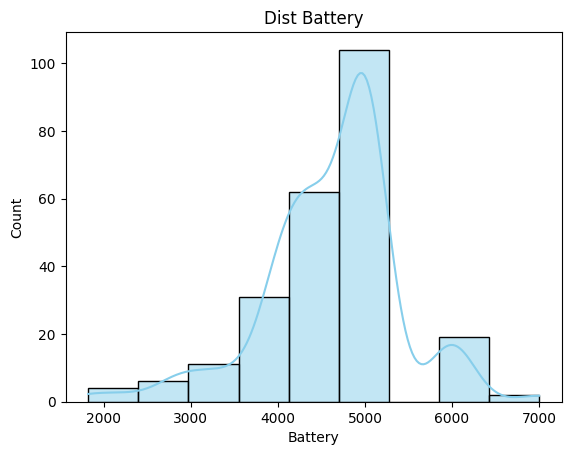

In [53]:
sns.histplot(
    df['Battery Capacity (mAh)'], bins='sturges', color="skyblue", kde=True
)
plt.title('Dist Battery')
plt.ylabel("Count")
plt.xlabel("Battery")

## Main_Camera_MP

In [54]:
df['Main_Camera_MP'].unique()

array([ 12. , 108. ,  48. ,  64. ,  50. ,  13. ,   8. ,  25. ,  12.2,
        40. ,  16. ])

In [55]:
df['Main_Camera_MP'].nunique()

11

In [56]:
dist_main_camera = pd.concat(
    [
        df["Main_Camera_MP"].value_counts(),
        df["Main_Camera_MP"].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_main_camera

,Count,Percentage (%)
Main_Camera_MP,,
48.0,73,30.54
64.0,50,20.92
13.0,38,15.90
50.0,27,11.30
12.0,26,10.88
108.0,12,5.02
8.0,5,2.09
12.2,3,1.26
40.0,2,0.84


In [57]:
df['Main_Camera_MP'].describe()

,Main_Camera_MP
count,239.000000
mean,43.387448
std,24.752476
min,8.000000
25%,13.000000
50%,48.000000
75%,64.000000
max,108.000000


In [58]:
# Skewness
skew = df['Main_Camera_MP'].skew()

# Kurtosis
kurt = df['Main_Camera_MP'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Main_Camera_MP'].quantile(0.25)
q3 = df['Main_Camera_MP'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Main_Camera_MP'].mean()

# Std (Simpangan Baku)
std = df['Main_Camera_MP'].std()

# Median (Nilai Tengah)
median = df['Main_Camera_MP'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Main_Camera_MP'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 43.38744769874477
Std = 24.752475671369673
Median = 48.0
Mode = 48.0
Skewness = 0.4077983546089423
Kurtosis = 0.26554222266433003
IQR = 51.0


Text(0.5, 0, 'Main Camera')

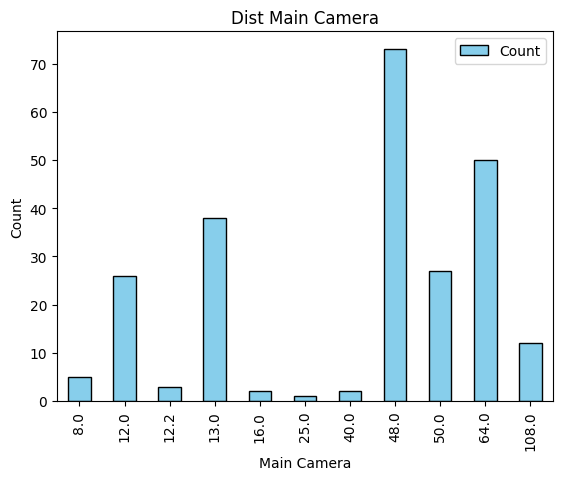

In [59]:
dist_main_camera.sort_index().plot(
    kind="bar", y="Count", color="skyblue", edgecolor="black"
)
plt.title('Dist Main Camera')
plt.ylabel("Count")
plt.xlabel("Main Camera")

## Camera_Count

In [60]:
df['Camera_Count'].unique()

array([3, 4, 2, 1])

In [61]:
df['Camera_Count'].nunique()

4

In [62]:
dist_camera_count = pd.concat(
    [
        df['Camera_Count'].value_counts(),
        df['Camera_Count'].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_camera_count

,Count,Percentage (%)
Camera_Count,,
3,115,48.12
4,73,30.54
2,46,19.25
1,5,2.09


In [63]:
df['Camera_Count'].describe()

,Camera_Count
count,239.00000
mean,3.07113
std,0.76089
min,1.00000
25%,3.00000
50%,3.00000
75%,4.00000
max,4.00000


In [64]:
# Skewness
skew = df['Camera_Count'].skew()

# Kurtosis
kurt = df['Camera_Count'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Camera_Count'].quantile(0.25)
q3 = df['Camera_Count'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Camera_Count'].mean()

# Std (Simpangan Baku)
std = df['Camera_Count'].std()

# Median (Nilai Tengah)
median = df['Camera_Count'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Camera_Count'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 3.071129707112971
Std = 0.760889558398699
Median = 3.0
Mode = 3
Skewness = -0.40868144490814323
Kurtosis = -0.37840904632999406
IQR = 1.0


Text(0.5, 0, 'Total Camera')

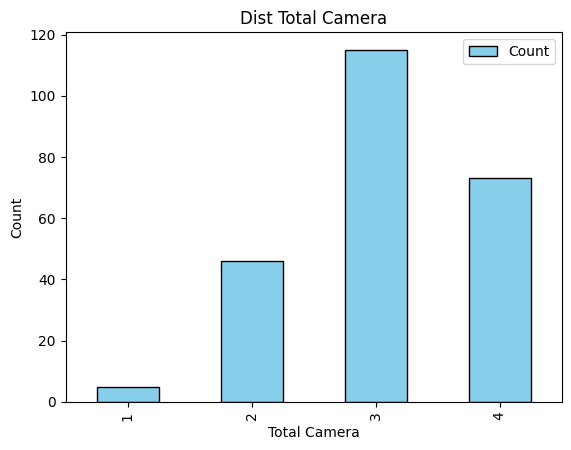

In [65]:
dist_camera_count.sort_index().plot(
    kind="bar", y="Count", color="skyblue", edgecolor="black"
)
plt.title('Dist Total Camera')
plt.ylabel("Count")
plt.xlabel("Total Camera")

## Total_Camera_MP

In [66]:
df['Total_Camera_MP'].unique()

array([ 36. , 140. , 108. ,  79. ,  62.2,  24. ,  60. ,  81. , 118. ,
        74. ,  86. , 116. ,  77. ,  88. ,  54. ,  52. ,  62. ,  53. ,
       100. , 123. ,  17. ,  15. ,  12. ,  55. ,  76. ,  61. ,  72. ,
        57. ,  89. ,  66. , 132. ,  84. ,  18. ,  73. , 146. ,  10. ,
        32. ,  82. ,  25. ,  58. ,  50. , 120. ,  13. ,  63. ,  20. ,
         8. ,  22. ,  28. ,  16. ,  23. ,  38. ,  28.2,  80. , 126. ,
        71. , 102. ,  65. , 109. ,  68. ,  29. ,  34. , 168. ])

In [67]:
df['Total_Camera_MP'].nunique()

62

In [68]:
dist_total_mp = pd.concat(
    [
        df['Total_Camera_MP'].value_counts(),
        df['Total_Camera_MP'].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_total_mp.head(10)

,Count,Percentage (%)
Total_Camera_MP,,
60.0,21,8.79
17.0,18,7.53
52.0,13,5.44
76.0,13,5.44
58.0,11,4.60
24.0,10,4.18
15.0,9,3.77
86.0,9,3.77
74.0,8,3.35


In [69]:
df['Total_Camera_MP'].describe()

,Total_Camera_MP
count,239.000000
mean,57.584937
std,30.977804
min,8.000000
25%,28.200000
50%,60.000000
75%,76.000000
max,168.000000


In [70]:
# Skewness
skew = df['Total_Camera_MP'].skew()

# Kurtosis
kurt = df['Total_Camera_MP'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Total_Camera_MP'].quantile(0.25)
q3 = df['Total_Camera_MP'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Total_Camera_MP'].mean()

# Std (Simpangan Baku)
std = df['Total_Camera_MP'].std()

# Median (Nilai Tengah)
median = df['Total_Camera_MP'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Total_Camera_MP'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 57.58493723849372
Std = 30.977803504687618
Median = 60.0
Mode = 60.0
Skewness = 0.5063127228855098
Kurtosis = 0.35538835224788334
IQR = 47.8


Text(0.5, 0, 'Total MP')

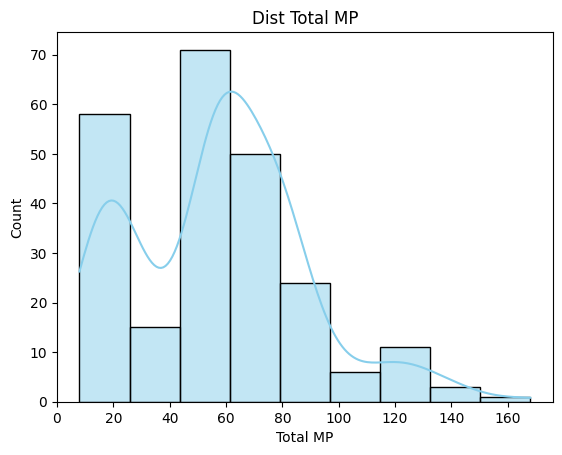

In [71]:
sns.histplot(
    df['Total_Camera_MP'], bins='sturges', color="skyblue", kde=True
)
plt.title('Dist Total MP')
plt.ylabel("Count")
plt.xlabel("Total MP")

## Price (Dependen Variable)

In [72]:
df['Price ($)'].unique()

array([ 999, 1199,  899,  279,  799,  249,  699,  329,  449,  199,  299,
        379,  179,  729,  599,  139,  189,  399,  259,  159,  229,  499,
        129,  529,  369, 1099,  169,   99,  239, 1299,  429,  659,  269,
        359,  549,  349,  149,  219,  389,  309,  339,  319,  209,  119,
        289,  130,  749,  649, 1399, 1999])

In [73]:
df['Price ($)'].unique()

array([ 999, 1199,  899,  279,  799,  249,  699,  329,  449,  199,  299,
        379,  179,  729,  599,  139,  189,  399,  259,  159,  229,  499,
        129,  529,  369, 1099,  169,   99,  239, 1299,  429,  659,  269,
        359,  549,  349,  149,  219,  389,  309,  339,  319,  209,  119,
        289,  130,  749,  649, 1399, 1999])

In [74]:
df['Price ($)'].nunique()

50

In [75]:
dist_price = pd.concat(
    [
        df['Price ($)'].value_counts(),
        df['Price ($)'].value_counts(normalize=True).mul(100).round(2),
    ],
    axis=1,
    keys=["Count", "Percentage (%)"],)
dist_price.head(10)

,Count,Percentage (%)
Price ($),,
279,16,6.69
199,13,5.44
299,13,5.44
699,12,5.02
399,12,5.02
249,11,4.60
329,10,4.18
999,10,4.18
179,10,4.18


In [76]:
df['Price ($)'].describe()

,Price ($)
count,239.000000
mean,436.410042
std,327.792321
min,99.000000
25%,199.000000
50%,299.000000
75%,574.000000
max,1999.000000


In [77]:
# Skewness
skew = df['Price ($)'].skew()

# Kurtosis
kurt = df['Price ($)'].kurtosis()

# IQR (Q3 - Q1)
q1 = df['Price ($)'].quantile(0.25)
q3 = df['Price ($)'].quantile(0.75)
iqr = q3 - q1

# Mean (Rata-rata)
mean = df['Price ($)'].mean()

# Std (Simpangan Baku)
std = df['Price ($)'].std()

# Median (Nilai Tengah)
median = df['Price ($)'].median()

# Mode (Nilai Paling Sering Muncul)
mode = df['Price ($)'].mode()[0]

print(f"Mean = {mean}")
print(f"Std = {std}")
print(f"Median = {median}")
print(f"Mode = {mode}")
print(f"Skewness = {skew}")
print(f"Kurtosis = {kurt}")
print(f"IQR = {iqr}")

Mean = 436.41004184100416
Std = 327.7923213700374
Median = 299.0
Mode = 279
Skewness = 1.5406853589794782
Kurtosis = 2.265339657012113
IQR = 375.0


Text(0.5, 0, 'Price')

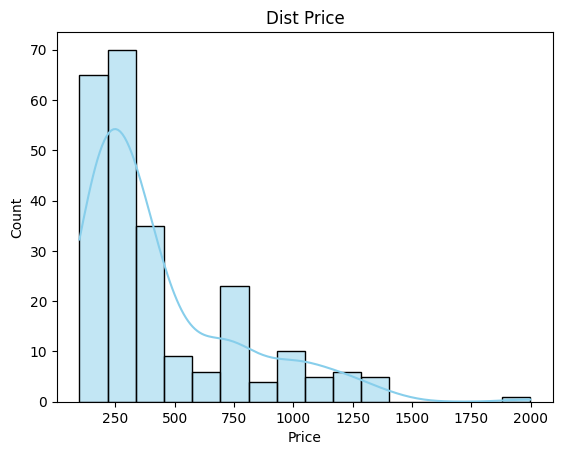

In [78]:
sns.histplot(
    df['Price ($)'], bins='fd', color="skyblue", kde=True
)
plt.title('Dist Price')
plt.ylabel("Count")
plt.xlabel("Price")

In [79]:
df[df['Screen Size (inches)'] > 7]

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Camera_Clean,Main_Camera_MP,Camera_Count,Total_Camera_MP
227,Samsung,Galaxy Z Fold2 5G,256,12,7.6,12+12+12,4500,1999,12+12+12,12.0,3,36.0


# Data Transformation

In [80]:
#8 brand terbesar
top_brands = df["Brand"].value_counts().nlargest(8).index.tolist()

#other than that 8 brand, anggap baseline atau other
df["Brand_Grouped"] = df["Brand"].apply(
    lambda x: x if x in top_brands else "0_Others"
)

#other as baseline
df = pd.get_dummies(
    df, columns=["Brand_Grouped"], drop_first=True, dtype=int
)
df.head()

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Camera_Clean,Main_Camera_MP,Camera_Count,Total_Camera_MP,Brand_Grouped_Apple,Brand_Grouped_Motorola,Brand_Grouped_Nokia,Brand_Grouped_Oppo,Brand_Grouped_Realme,Brand_Grouped_Samsung,Brand_Grouped_Vivo,Brand_Grouped_Xiaomi
0,Apple,iPhone 13 Pro,128,6,6.10,12 + 12 + 12,3095,999,12+12+12,12.0,3,36.0,1,0,0,0,0,0,0,0
1,Samsung,Galaxy S21 Ultra,256,12,6.80,108 + 10 + 10 + 12,5000,1199,108+10+10+12,108.0,4,140.0,0,0,0,0,0,1,0,0
2,OnePlus,9 Pro,128,8,6.70,48 + 50 + 8 + 2,4500,899,48+50+8+2,48.0,4,108.0,0,0,0,0,0,0,0,0
3,Xiaomi,Redmi Note 10 Pro,128,6,6.67,64 + 8 + 5 + 2,5020,279,64+8+5+2,64.0,4,79.0,0,0,0,0,0,0,0,1
4,Google,Pixel 6,128,8,6.40,50 + 12.2,4614,799,50+12.2,50.0,2,62.2,0,0,0,0,0,0,0,0


<h3>Other digunakan sebagai Baseline = 0</h3>

<h3>Varibale yang akan digunakan: <br><br>
IV: 'Storage', 'RAM', 'Screen Size (inches)','Camera (MP)',
'Battery Capacity (mAh)','Main_Camera_MP', 'Camera_Count',
'Total_Camera_MP','Brand_Grouped_Apple', 'Brand_Grouped_Motorola',
'Brand_Grouped_Nokia','Brand_Grouped_Oppo', 'Brand_Grouped_Realme',
'Brand_Grouped_Samsung','Brand_Grouped_Vivo', 'Brand_Grouped_Xiaomi' <br><br>
DV: 'Price ($)'</h3>

In [81]:
### Transformasi logaritma mengubah selisih harga dari skala nominal Dolar yang kaku menjadi persentase perubahan
## yang proporsional terhadap harga awal (base price) masing-masing ponsel. Cara ini membuat variasi kesalahan prediksi
### (residual) pada HP murah maupun HP mahal menjadi setara dan stabil, sehingga masalah heteroskedastisitas dapat teratasi.
df['Price ($)'] = np.log(df['Price ($)'])

Text(0.5, 0, 'Price')

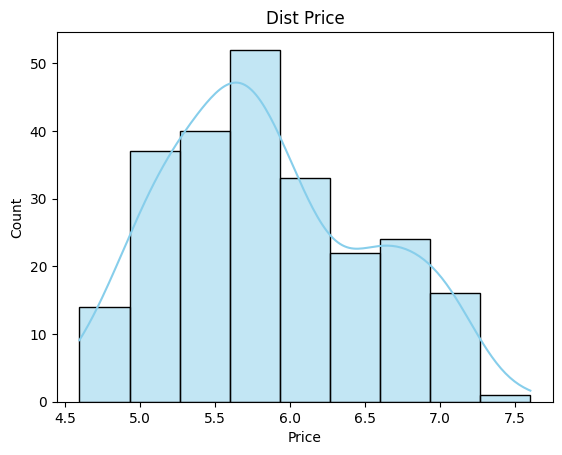

In [82]:
sns.histplot(
    df['Price ($)'], bins='fd', color="skyblue", kde=True
)
plt.title('Dist Price')
plt.ylabel("Count")
plt.xlabel("Price")

# Assumption Pre-Fitting

## 1. Linearity

In [83]:
iv = ['Storage', 'RAM', 'Screen Size (inches)', 'Battery Capacity (mAh)','Main_Camera_MP', 'Camera_Count', 'Total_Camera_MP','Brand_Grouped_Apple', 'Brand_Grouped_Motorola', 'Brand_Grouped_Nokia','Brand_Grouped_Oppo', 'Brand_Grouped_Realme', 'Brand_Grouped_Samsung','Brand_Grouped_Vivo', 'Brand_Grouped_Xiaomi']

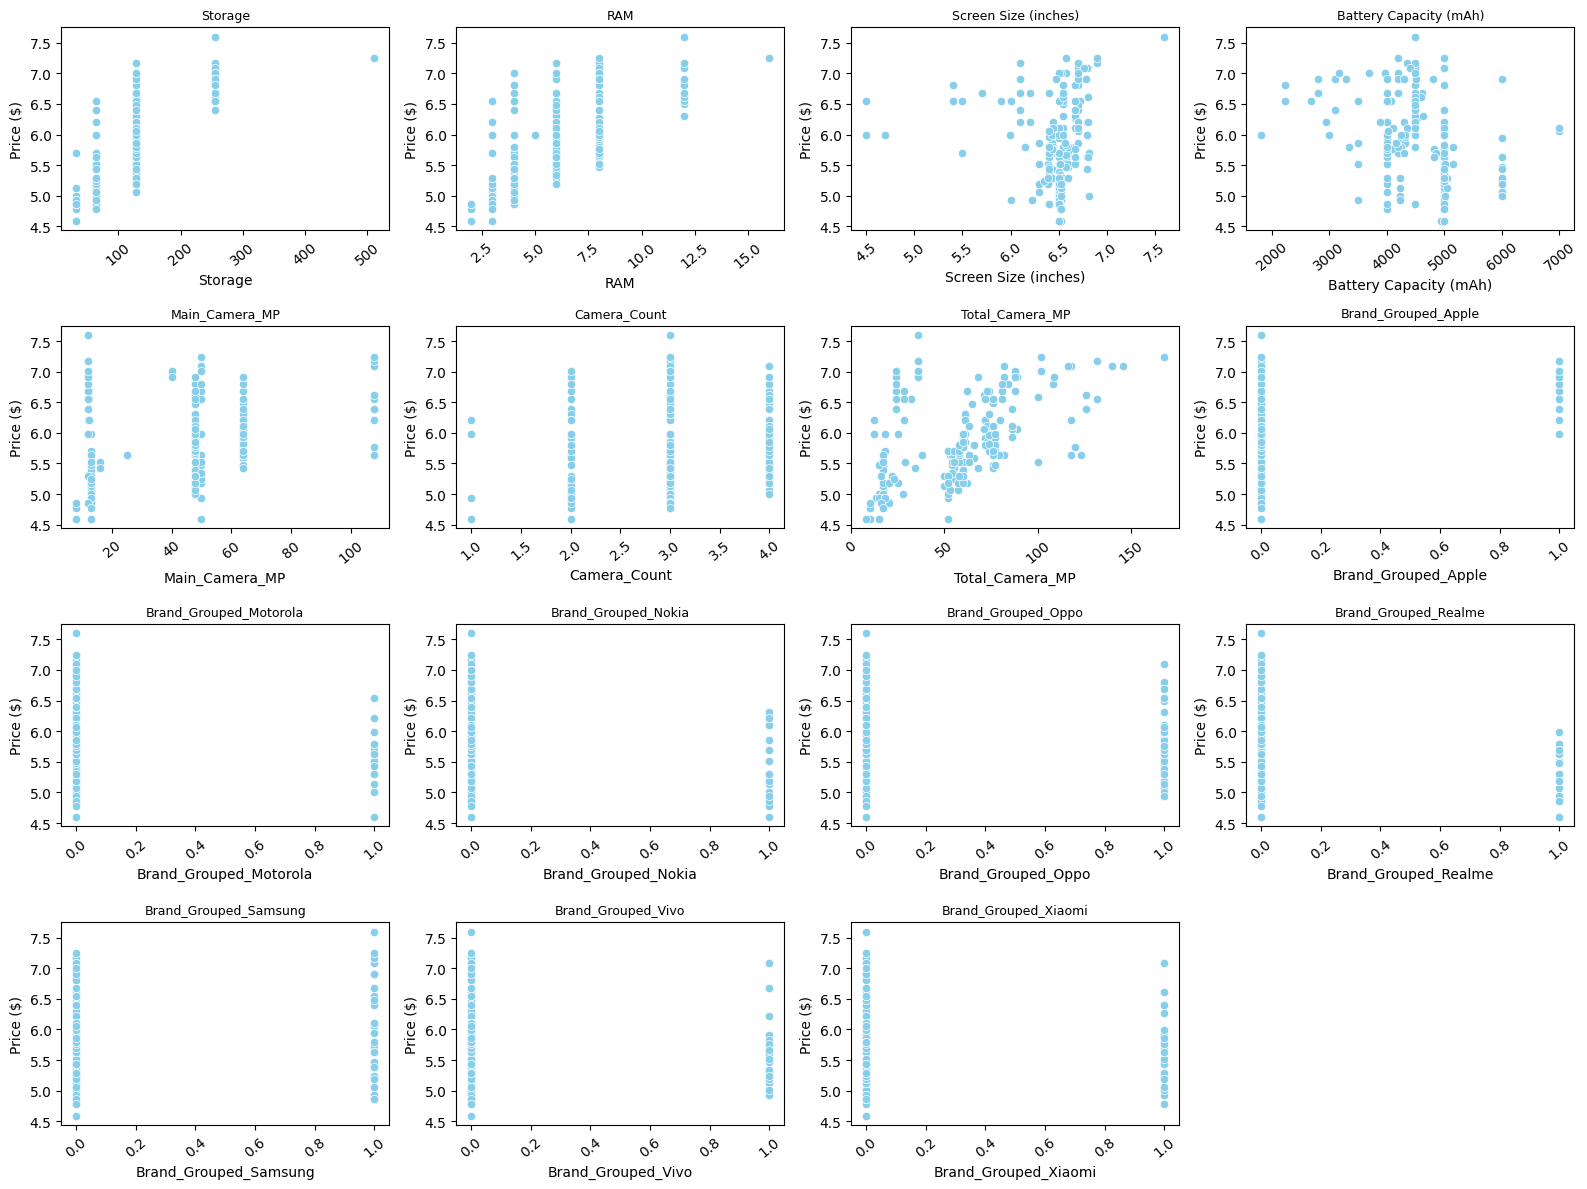

In [84]:
n_cols = 4
n_rows = math.ceil(len(iv) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.flatten()

for i, col in enumerate(iv):
    sns.scatterplot(data=df, x=col, y="Price ($)", ax=axes[i], color="skyblue")
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(axis="x", rotation=40)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

## 2. Outlier

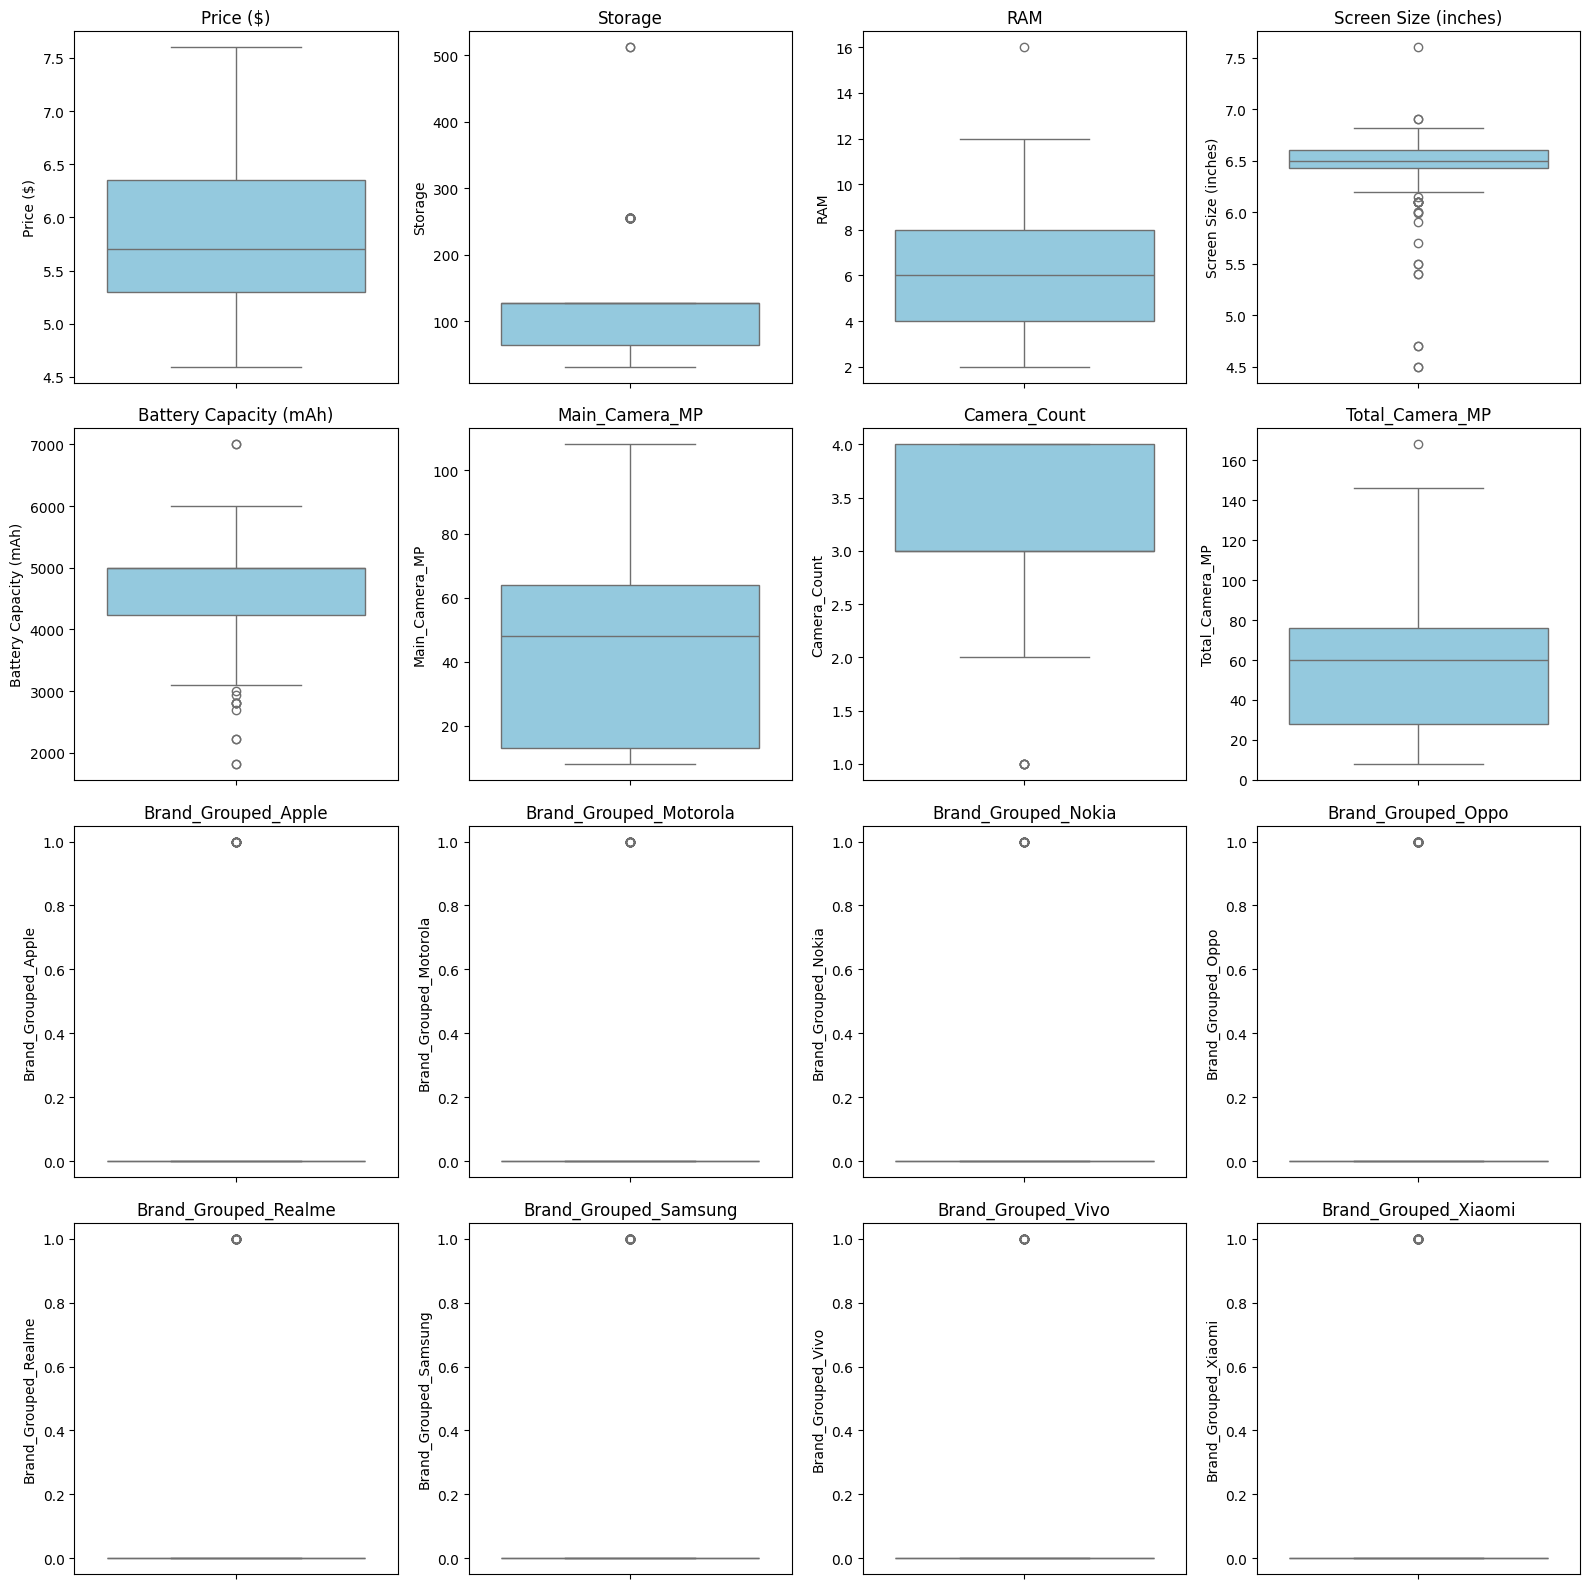

In [85]:
all_vars = ["Price ($)"] + iv

# 1. Tentukan jumlah kolom yang diinginkan
n_cols = 4

# 2. Hitung jumlah baris secara otomatis agar selalu pas untuk berapa pun variabel di all_vars
n_rows = math.ceil(len(all_vars) / n_cols)

# 3. Buat grid subplot dengan n_rows dinamis
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

# 4. Loop plotting
for i, col in enumerate(all_vars):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col)

# 5. Hapus sisa slot subplot yang kosong di baris terakhir
for i in range(len(all_vars), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [86]:
def find_outliers_iqr(dataframe, columns):
    outliers_dict = {}
    for col in columns:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Filter data yang di luar batas IQR
        outliers = dataframe[(dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)]
        outliers_dict[col] = len(outliers)

    return pd.DataFrame(list(outliers_dict.items()), columns=['Variable', 'Outlier Count'])

# Cek jumlah outlier untuk semua variabel
all_vars = ['Price ($)'] + iv
outlier_summary = find_outliers_iqr(df, all_vars)
print(outlier_summary)

                  Variable  Outlier Count
0                Price ($)              0
1                  Storage             34
2                      RAM              1
3     Screen Size (inches)             24
4   Battery Capacity (mAh)             13
5           Main_Camera_MP              0
6             Camera_Count              5
7          Total_Camera_MP              1
8      Brand_Grouped_Apple             15
9   Brand_Grouped_Motorola             19
10     Brand_Grouped_Nokia             17
11      Brand_Grouped_Oppo             33
12    Brand_Grouped_Realme             24
13   Brand_Grouped_Samsung             42
14      Brand_Grouped_Vivo             21
15    Brand_Grouped_Xiaomi             33


## 3. Multikolinearitas

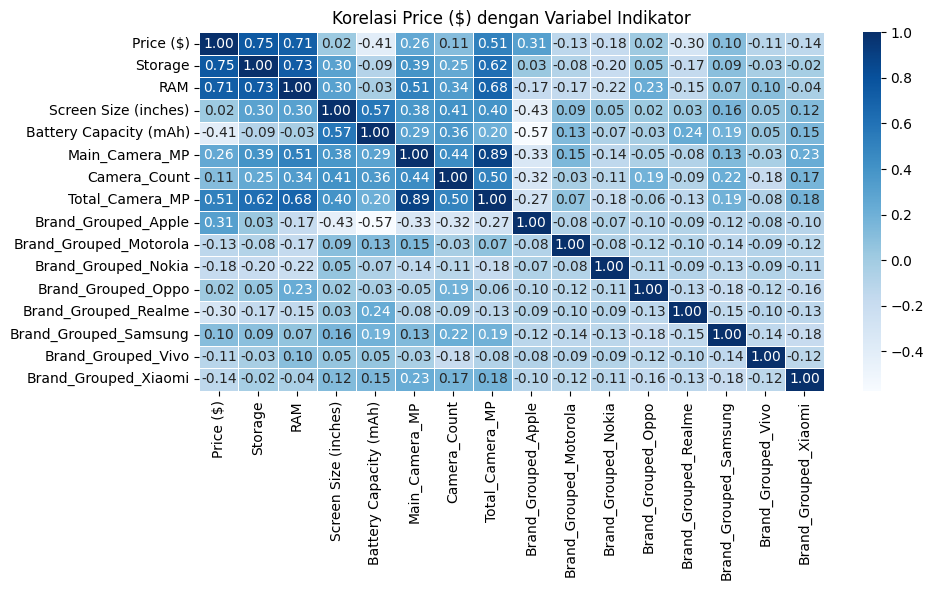

In [87]:
selected_cols = ['Price ($)'] + iv
corr_selected = df[selected_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_selected,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Korelasi Price ($) dengan Variabel Indikator')
plt.tight_layout()
plt.show()

In [88]:
X = df[iv].dropna()

X_with_const = df[iv].dropna().copy()
X_with_const['intercept'] = 1

vif_data = pd.DataFrame()
vif_data['Variable'] = iv
vif_data['VIF'] = [
    variance_inflation_factor(X_with_const.values, X_with_const.columns.get_loc(col))
    for col in iv
]

vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)
print(vif_data)

                  Variable        VIF
0          Total_Camera_MP  11.482952
1           Main_Camera_MP   7.046630
2                      RAM   3.940149
3                  Storage   3.105154
4   Battery Capacity (mAh)   2.479058
5    Brand_Grouped_Samsung   2.231761
6     Brand_Grouped_Xiaomi   2.171154
7     Screen Size (inches)   2.111224
8       Brand_Grouped_Oppo   2.029888
9     Brand_Grouped_Realme   1.970845
10  Brand_Grouped_Motorola   1.884393
11     Brand_Grouped_Apple   1.871494
12      Brand_Grouped_Vivo   1.770929
13            Camera_Count   1.755022
14     Brand_Grouped_Nokia   1.713650


<h3> thereshold yang kita gunakan adalah: <br><br>
<li>Correlation must less than |0.8|</li><br>
<li>VIF must less than 5</li><br>
<bold>Hence here we dropped: Main-camera-mp because....</bold>

In [89]:
#dropping main-camera-mp
iv = ['Storage', 'RAM', 'Screen Size (inches)', 'Battery Capacity (mAh)','Camera_Count', 'Total_Camera_MP','Brand_Grouped_Apple', 'Brand_Grouped_Motorola', 'Brand_Grouped_Nokia','Brand_Grouped_Oppo', 'Brand_Grouped_Realme', 'Brand_Grouped_Samsung','Brand_Grouped_Vivo', 'Brand_Grouped_Xiaomi']

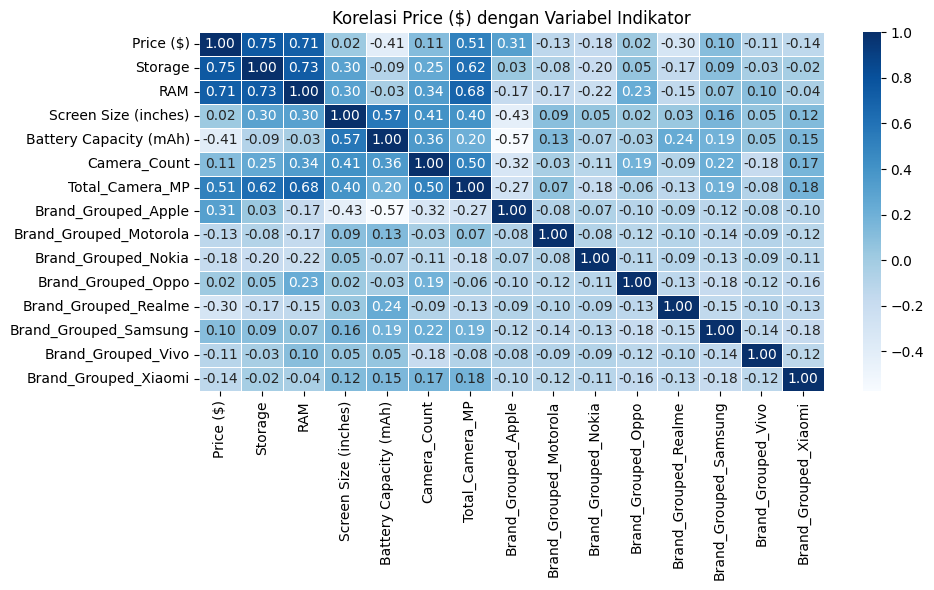

In [90]:
selected_cols = ['Price ($)'] + iv
corr_selected = df[selected_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_selected,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Korelasi Price ($) dengan Variabel Indikator')
plt.tight_layout()
plt.show()

In [91]:
X = df[iv].dropna()

X_with_const = df[iv].dropna().copy()
X_with_const['intercept'] = 1

vif_data = pd.DataFrame()
vif_data['Variable'] = iv
vif_data['VIF'] = [
    variance_inflation_factor(X_with_const.values, X_with_const.columns.get_loc(col))
    for col in iv
]

vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)
print(vif_data)

                  Variable       VIF
0                      RAM  3.909511
1          Total_Camera_MP  3.278482
2                  Storage  2.840109
3   Battery Capacity (mAh)  2.467133
4    Brand_Grouped_Samsung  2.230454
5     Brand_Grouped_Xiaomi  2.131875
6     Screen Size (inches)  2.108722
7       Brand_Grouped_Oppo  1.974619
8     Brand_Grouped_Realme  1.954809
9      Brand_Grouped_Apple  1.871256
10  Brand_Grouped_Motorola  1.847458
11            Camera_Count  1.742915
12      Brand_Grouped_Vivo  1.728977
13     Brand_Grouped_Nokia  1.706952


In [92]:
df

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Camera_Clean,Main_Camera_MP,Camera_Count,Total_Camera_MP,Brand_Grouped_Apple,Brand_Grouped_Motorola,Brand_Grouped_Nokia,Brand_Grouped_Oppo,Brand_Grouped_Realme,Brand_Grouped_Samsung,Brand_Grouped_Vivo,Brand_Grouped_Xiaomi
0,Apple,iPhone 13 Pro,128,6,6.10,12 + 12 + 12,3095,6.906755,12+12+12,12.0,3,36.0,1,0,0,0,0,0,0,0
1,Samsung,Galaxy S21 Ultra,256,12,6.80,108 + 10 + 10 + 12,5000,7.089243,108+10+10+12,108.0,4,140.0,0,0,0,0,0,1,0,0
2,OnePlus,9 Pro,128,8,6.70,48 + 50 + 8 + 2,4500,6.801283,48+50+8+2,48.0,4,108.0,0,0,0,0,0,0,0,0
3,Xiaomi,Redmi Note 10 Pro,128,6,6.67,64 + 8 + 5 + 2,5020,5.631212,64+8+5+2,64.0,4,79.0,0,0,0,0,0,0,0,1
4,Google,Pixel 6,128,8,6.40,50 + 12.2,4614,6.683361,50+12.2,50.0,2,62.2,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
234,Motorola,Moto G Pro,128,4,6.40,48+16+2,4000,5.796058,48+16+2,48.0,3,66.0,0,1,0,0,0,0,0,0
235,Huawei,P30 Lite,128,4,6.15,48+8+2,3340,5.796058,48+8+2,48.0,3,58.0,0,0,0,0,0,0,0,0
236,Xiaomi,Mi 10 Lite 5G,128,6,6.57,48+8+2+2,4160,5.855072,48+8+2+2,48.0,4,60.0,0,0,0,0,0,0,0,1
237,Apple,iPhone 12 Pro Max,128,6,6.70,12+12+12,3687,7.002156,12+12+12,12.0,3,36.0,1,0,0,0,0,0,0,0


In [93]:
iv

['Storage',
 'RAM',
 'Screen Size (inches)',
 'Battery Capacity (mAh)',
 'Camera_Count',
 'Total_Camera_MP',
 'Brand_Grouped_Apple',
 'Brand_Grouped_Motorola',
 'Brand_Grouped_Nokia',
 'Brand_Grouped_Oppo',
 'Brand_Grouped_Realme',
 'Brand_Grouped_Samsung',
 'Brand_Grouped_Vivo',
 'Brand_Grouped_Xiaomi']

In [94]:
df

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($),Camera_Clean,Main_Camera_MP,Camera_Count,Total_Camera_MP,Brand_Grouped_Apple,Brand_Grouped_Motorola,Brand_Grouped_Nokia,Brand_Grouped_Oppo,Brand_Grouped_Realme,Brand_Grouped_Samsung,Brand_Grouped_Vivo,Brand_Grouped_Xiaomi
0,Apple,iPhone 13 Pro,128,6,6.10,12 + 12 + 12,3095,6.906755,12+12+12,12.0,3,36.0,1,0,0,0,0,0,0,0
1,Samsung,Galaxy S21 Ultra,256,12,6.80,108 + 10 + 10 + 12,5000,7.089243,108+10+10+12,108.0,4,140.0,0,0,0,0,0,1,0,0
2,OnePlus,9 Pro,128,8,6.70,48 + 50 + 8 + 2,4500,6.801283,48+50+8+2,48.0,4,108.0,0,0,0,0,0,0,0,0
3,Xiaomi,Redmi Note 10 Pro,128,6,6.67,64 + 8 + 5 + 2,5020,5.631212,64+8+5+2,64.0,4,79.0,0,0,0,0,0,0,0,1
4,Google,Pixel 6,128,8,6.40,50 + 12.2,4614,6.683361,50+12.2,50.0,2,62.2,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
234,Motorola,Moto G Pro,128,4,6.40,48+16+2,4000,5.796058,48+16+2,48.0,3,66.0,0,1,0,0,0,0,0,0
235,Huawei,P30 Lite,128,4,6.15,48+8+2,3340,5.796058,48+8+2,48.0,3,58.0,0,0,0,0,0,0,0,0
236,Xiaomi,Mi 10 Lite 5G,128,6,6.57,48+8+2+2,4160,5.855072,48+8+2+2,48.0,4,60.0,0,0,0,0,0,0,0,1
237,Apple,iPhone 12 Pro Max,128,6,6.70,12+12+12,3687,7.002156,12+12+12,12.0,3,36.0,1,0,0,0,0,0,0,0


# Fitting Multiple Linear Regression

In [95]:
#mementukan x and y
X = df[iv].dropna().copy()
y = df.loc[X.index, 'Price ($)']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit(cov_type='HC3')

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              Price ($)   R-squared:                       0.865
Model:                            OLS   Adj. R-squared:                  0.856
Method:                 Least Squares   F-statistic:                     82.98
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           4.26e-80
Time:                        06:42:44   Log-Likelihood:                -5.3580
No. Observations:                 238   AIC:                             40.72
Df Residuals:                     223   BIC:                             92.80
Df Model:                          14                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      4.9326      0.771      6.395      0.000       3.421       6.444
Storage                    0.0022      0.001      3.589      0.000       0.001       0.003
RAM                        0.1289      0.017      7.569      0.000       0.096       0.162
Screen Size (inches)       0.1134      0.139      0.813      0.416      -0.160       0.387
Battery Capacity (mAh)    -0.0001   4.34e-05     -3.096      0.002      -0.000   -4.93e-05
Camera_Count              -0.0333      0.035     -0.960      0.337      -0.101       0.035
Total_Camera_MP            0.0023      0.001      1.720      0.085      -0.000       0.005
Brand_Grouped_Apple        0.6066      0.098      6.173      0.000       0.414       0.799
Brand_Grouped_Motorola    -0.3399      0.103     -3.309      0.001      -0.541      -0.139
Brand_Grouped_Nokia       -0.3445      0.109     -3.165      0.002      -0.558      -0.131
Brand_Grouped_Oppo        -0.4535      0.090     -5.025      0.000      -0.630      -0.277
Brand_Grouped_Realme      -0.5691      0.094     -6.057      0.000      -0.753      -0.385
Brand_Grouped_Samsung     -0.1985      0.106     -1.868      0.062      -0.407       0.010
Brand_Grouped_Vivo        -0.5951      0.090     -6.608      0.000      -0.772      -0.419
Brand_Grouped_Xiaomi      -0.4707      0.089     -5.279      0.000      -0.645      -0.296
==============================================================================
Omnibus:                       10.704   Durbin-Watson:                   2.022
Prob(Omnibus):                  0.005   Jarque-Bera (JB):               22.883
Skew:                          -0.058   Prob(JB):                     1.07e-05
Kurtosis:                       4.515   Cond. No.                     1.13e+05
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 1.13e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [96]:
len(df)

239

# Assumption Post-Fitting

## 4. Independensi Residual

In [97]:
# 1. Ambil nilai residual dari model OLS
residuals = model.resid

# 2. Hitung statistik Durbin-Watson
dw_stat = durbin_watson(residuals)
print(f"Durbin-Watson statistic: {dw_stat:.4f}")

Durbin-Watson statistic: 2.0222


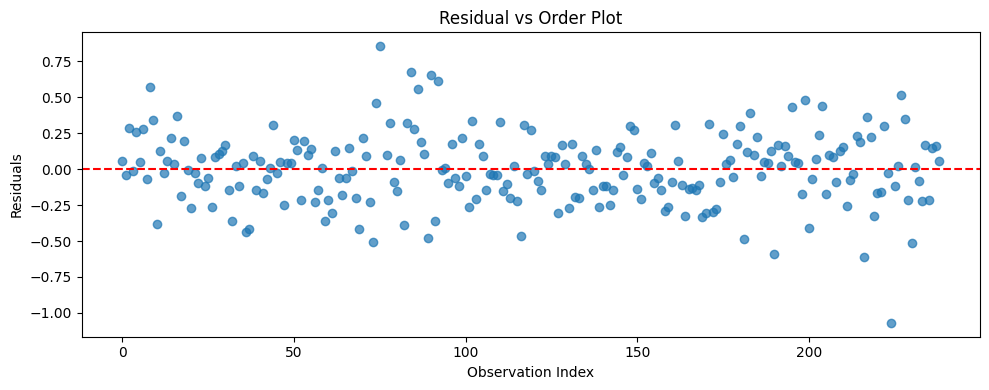

In [98]:
plt.figure(figsize=(10, 4))
plt.plot(residuals.index, residuals, marker='o', linestyle='', alpha=0.7)
plt.axhline(0, color='red', linestyle='--')

plt.title('Residual vs Order Plot')
plt.xlabel('Observation Index')
plt.ylabel('Residuals')
plt.tight_layout()
plt.show()

                    mean       std  count
Brand                                    
Apple       3.848773e-14  0.180242     15
Asus        3.455797e-01  0.256799      3
Blackberry  3.346948e-01  0.332656      3
CAT         2.770316e-01       NaN      1
Google      2.272512e-01  0.159922      4
Huawei     -7.698452e-02  0.313415     10
LG         -1.969428e-01  0.269087      2
Motorola   -6.217249e-15  0.212562     19
Nokia       1.097162e-14  0.235950     17
OnePlus    -2.918658e-01  0.270270     10
Oppo        1.485680e-14  0.161444     33
Realme      1.284158e-14  0.178148     24
Samsung    -2.051269e-15  0.336404     42
Sony        8.555291e-01       NaN      1
Vivo        1.234991e-14  0.166597     21
Xiaomi     -9.285502e-15  0.169253     33


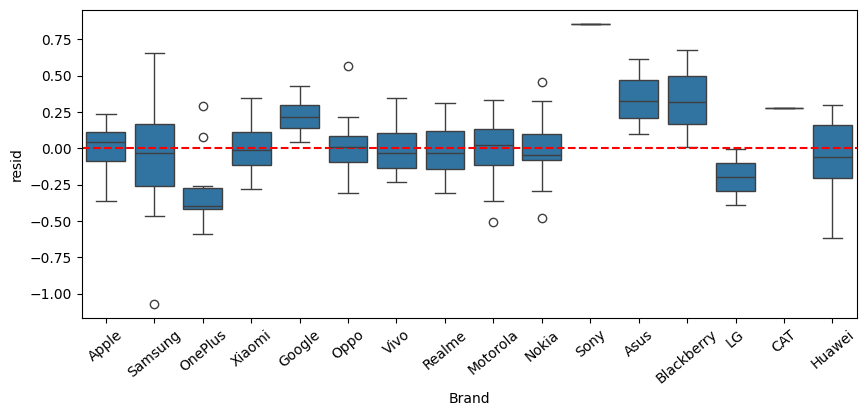

In [99]:
d = df.loc[X.index].assign(resid=model.resid)

print(d.groupby("Brand")["resid"].agg(["mean", "std", "count"]))

plt.figure(figsize=(10, 4))
sns.boxplot(data=d, x="Brand", y="resid")
plt.xticks(rotation=40)
plt.axhline(0, color="red", linestyle="--")
plt.show()

In [100]:
g = d.groupby("Model")["resid"].agg(["count", "mean", "std"])
print(g[g["count"] > 1].sort_values("count", ascending=False).head(15))

print("Jumlah model unik:", d["Model"].nunique(), "dari", len(d), "baris")

Empty DataFrame
Columns: [count, mean, std]
Index: []
Jumlah model unik: 238 dari 238 baris


## 5. Homoskedastisitas

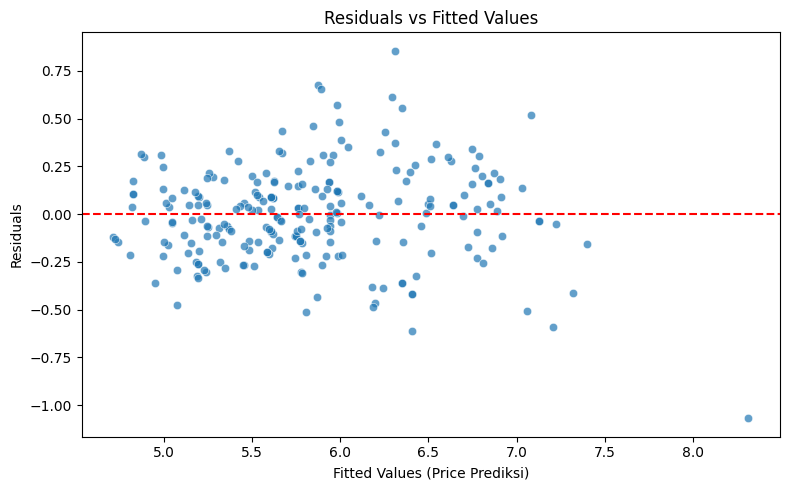

In [101]:
# Ambil fitted values dan residuals dari model OLS
fitted_vals = model.fittedvalues
residuals = model.resid

plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted_vals, y=residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')

plt.title('Residuals vs Fitted Values')
plt.xlabel('Fitted Values (Price Prediksi)')
plt.ylabel('Residuals')
plt.tight_layout()
plt.show()

In [102]:
# Uji Breusch-Pagan menggunakan residuals dan matriks variabel bebas (X)
bp_test = het_breuschpagan(model.resid, model.model.exog)

labels = ['LM Statistic', 'LM p-value', 'F-Statistic', 'F p-value']
for stat, value in zip(labels, bp_test):
    print(f"{stat}: {value:.4f}")

LM Statistic: 64.9403
LM p-value: 0.0000
F-Statistic: 5.9772
F p-value: 0.0000


## 6. Normalitas Residual

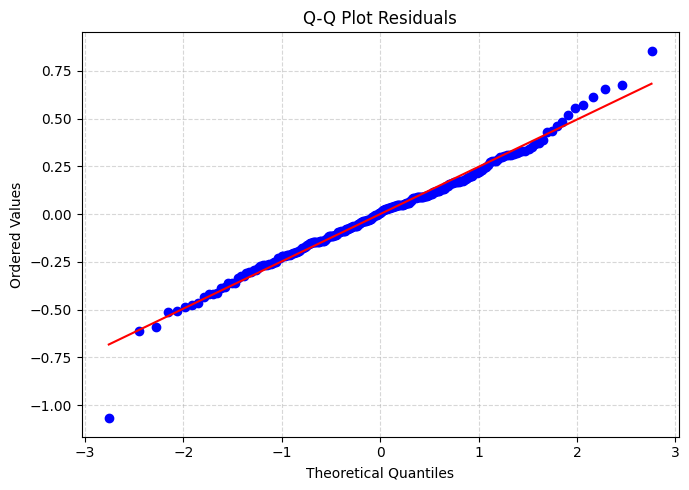

In [103]:
# Ambil residual dari model OLS
residuals = model.resid

plt.figure(figsize=(7, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot Residuals')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Ordered Values')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

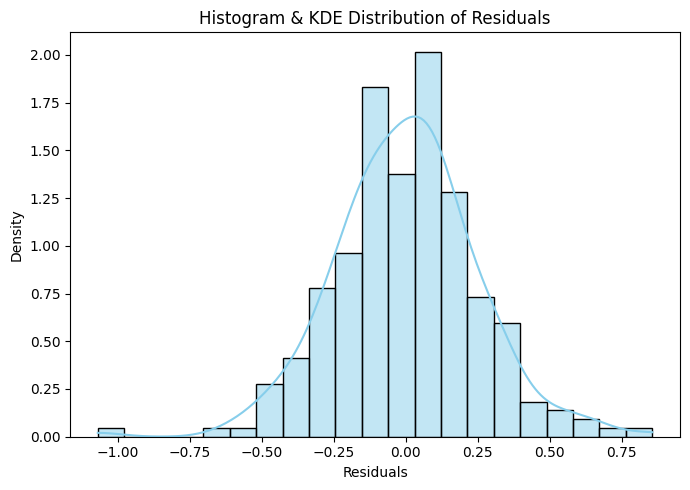

In [104]:
plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True, color='skyblue', stat='density')
plt.title('Histogram & KDE Distribution of Residuals')
plt.xlabel('Residuals')
plt.tight_layout()
plt.show()

In [105]:
# Uji Jarque-Bera
jb_stat, jb_pvalue = jarque_bera(model.resid)
print(f"Jarque-Bera p-value: {jb_pvalue:.5f}")

Jarque-Bera p-value: 0.00001


In [106]:
#Titik data yang paling menggeser model
infl = model.get_influence()
cooks = infl.cooks_distance[0]
d = df.loc[X.index].assign(resid=model.resid, cooks=cooks)

print(d.sort_values("cooks", ascending=False)[["Brand", "Model", "Price ($)", "resid", "cooks"]].head(5))

          Brand                Model  Price ($)     resid     cooks
224     Samsung  Galaxy S20 Ultra 5G   7.243513 -1.069388  0.328579
84   Blackberry                 KEY2   6.549651  0.675041  0.172539
227     Samsung    Galaxy Z Fold2 5G   7.600402  0.518937  0.085573
86      Samsung      Galaxy Z Flip 3   6.906755  0.556348  0.047431
75         Sony         Xperia 5 III   7.169350  0.855529  0.046875


In [107]:
resid = model.resid
sw_stat, sw_p = stats.shapiro(resid)

print(f"Shapiro-Wilk W: {sw_stat:.4f}")
print(f"p-value       : {sw_p:.4g}")

Shapiro-Wilk W: 0.9858
p-value       : 0.01819


In [108]:
sd = X.drop(columns="const").std()
pct_sd = (np.exp(model.params[sd.index] * sd) - 1) * 100
print(pct_sd.round(1))

Storage                   16.8
RAM                       39.1
Screen Size (inches)       3.9
Battery Capacity (mAh)   -10.0
Camera_Count              -2.5
Total_Camera_MP            7.3
Brand_Grouped_Apple       15.9
Brand_Grouped_Motorola    -8.8
Brand_Grouped_Nokia       -8.5
Brand_Grouped_Oppo       -14.5
Brand_Grouped_Realme     -15.8
Brand_Grouped_Samsung     -7.3
Brand_Grouped_Vivo       -15.6
Brand_Grouped_Xiaomi     -15.0
dtype: float64
